In [1]:
import xarray as xr
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import cartopy.crs as ccrs #for plotting

# alternative to this is: from acacia_s2s_toolkit.postprocess import *

from acacia_s2s_toolkit.postprocess import (read_netcdf, 
                                            hcst_to_effective_lead_time,
                                            set_verbose, 
                                            hcst_to_effective_lead_time, 
                                            fcst_to_effective_lead_time,
                                            align_grid,
                                            align_obs_to_model_time,
                                            aggregate,
                                            )

from acacia_s2s_toolkit.bias_correction import bias_correct
from acacia_s2s_toolkit.products import make_deterministic_product, make_probabilistic_product


In [2]:
# defining what you want to process - i.e. forecast date, domain and observed dataset

data_dir="./data" #where data files are read from

#date of the file - also treated here as the nominal date of the forecast, i.e. date for which forecast was requested.
nominal_date="2026-10-05" 
nominal_date="2025-12-01" 

target_domain="madagascar" #target domain
fcst_var="tp" #forecast variable
fcst_model="ECMWF" #forecast model
window_size=7 #size of the aggregation window


#this is file with observational data. It is gridded and covers the period of Jan 1981-March 2026
# any file with daily historical data should do, but if you don't have one at hand - you can get this one by:
#get_example_data(data_dir)
obs_file=f"{data_dir}/PRCPTOT_day_CHC_CHIRPS-2.0-0p25_merged.nc"

#we have to provide the name of the variable stored in the obs_file
obs_var="PRCPTOT"

# this is a file with vector data showing the boundaries of the domain - will be used in plotting only, so not strictly necessary
# this one is included in the example data that comes through get_example_data()
domain_shape_file=f"{data_dir}/madagascar.geojson"

# this defines regridding parameters for matching the obs and forecast grids. 
# it assumes obs grid is finer, so fine_to_coarse will give forecast grid, coarse_to_fine will give obs grid
# raise_if_missing will stop processing if the spatial overlap between obs and forecast grids of less than fractional 
# threshold

grid_alignment_kwargs=dict(
    direction="coarse_to_fine",
    method="bilinear",
    raise_if_missing=True,
    threshold=0.9
)

# this defines time alignment parameter for matching the obs and hindcast time series. 
# raise_if_missing will stop processing if any of the hindcast days are not covered by observations 
time_alignment_kwargs={"raise_if_missing":True}

# this sets global verbosity variable. True will show runtime feedback 
set_verbose(False)

#deriving secondary parameters
fcst_date=pd.to_datetime(nominal_date)
fcst_date_str=fcst_date.strftime("%Y%m%d")

# constructing names of data files based on the information above
# forecast data file
fcst_file="{}/{}_{}_{}_{}_fc.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)

# hindcast data file
hcst_file="{}/{}_{}_{}_{}_hc.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)


verbosity is False


In [3]:

#=============================================================
# prelim stuff - reading and organizing data...
# one has to start with this in any pipeline

#reading forecast data - the read_netcdf() wraps xr.open_mfdataset() adding some checks
fcst_raw=read_netcdf(fcst_file, fcst_var)

#reading hindast
hcst_raw=read_netcdf(hcst_file, fcst_var)

#rainfall hindcast comes with some negative values 
hcst_raw=hcst_raw.where(hcst_raw>0,0)

# reading observed data
obs_raw=read_netcdf(obs_file, obs_var)

print("raw data")
print("fcst: ",fcst_raw.sizes)
print("hindcast: ", hcst_raw.sizes)
print("observed:", obs_raw.sizes)

raw data
fcst:  Frozen({'valid_time': 29, 'member': 202, 'latitude': 11, 'longitude': 7})
hindcast:  Frozen({'hc_init_date': 40, 'lead_time': 29, 'member': 11, 'latitude': 11, 'longitude': 7})
observed: Frozen({'time': 16467, 'latitude': 58, 'longitude': 36})


In [4]:
hcst_raw#["hc_init_date"]

<xarray.DataArray 'tp' (hc_init_date: 40, lead_time: 29, member: 11,
                        latitude: 11, longitude: 7)> Size: 4MB
array([[[[[5.29296875e-01, 1.30078125e+00, 1.70703125e+00, ...,
           7.92968750e-01, 1.74218750e+00, 2.35742188e+00],
          [1.69335938e+00, 1.32617188e+00, 4.58203125e+00, ...,
           6.15234375e+00, 1.15234375e+00, 5.34960938e+00],
          [2.20703125e+00, 6.05468750e-01, 1.14960938e+01, ...,
           2.89843750e+00, 5.30664062e+00, 4.41796875e+00],
          ...,
          [1.54296875e-01, 2.75781250e+00, 1.35000000e+01, ...,
           2.48242188e+00, 8.94531250e-01, 2.48242188e+00],
          [9.76562500e-03, 0.00000000e+00, 3.90625000e-02, ...,
           1.16601562e+00, 1.30078125e+00, 4.94140625e-01],
          [7.03125000e-02, 2.32421875e-01, 7.42187500e-02, ...,
           2.85156250e-01, 1.81640625e-01, 4.68750000e-01]],

         [[2.69531250e-01, 7.42187500e-01, 1.63671875e+00, ...,
           2.46093750e-01, 4.49218750e+00, 1.29296875e+00],
          [8.43750000e-01, 7.77343750e-01, 3.01171875e+00, ...,
           6.05859375e+00, 5.39062500e-01, 5.87890625e+00],
          [9.25781250e-01, 1.79687500e-01, 6.79687500e+00, ...,
           5.09765625e+00, 4.68750000e+00, 7.09375000e+00],
...
           3.43750000e-01, 8.75000000e-01, 9.37500000e-02],
          [2.87500000e+00, 9.37500000e-02, 6.31250000e+00, ...,
           5.00000000e-01, 3.75000000e-01, 5.62500000e-01],
          [5.31250000e+00, 3.12500000e-01, 0.00000000e+00, ...,
           2.81250000e-01, 6.25000000e-01, 9.37500000e-02]],

         [[1.45312500e+00, 2.90625000e+00, 6.65625000e+00, ...,
           1.54375000e+01, 9.12500000e+00, 4.42187500e+00],
          [6.84375000e+00, 1.15781250e+01, 1.52343750e+01, ...,
           1.05468750e+01, 7.48437500e+00, 3.54687500e+00],
          [1.80781250e+01, 3.46562500e+01, 2.13906250e+01, ...,
           5.21875000e+00, 2.15625000e+00, 3.51562500e+00],
          ...,
          [9.06250000e-01, 3.95312500e+00, 1.26093750e+01, ...,
           2.20312500e+00, 1.68750000e+00, 1.71875000e+00],
          [6.56250000e-01, 1.23437500e+00, 5.46875000e-01, ...,
           4.57812500e+00, 1.15625000e+00, 9.21875000e-01],
          [5.46875000e-01, 1.40625000e-01, 9.37500000e-02, ...,
           1.79843750e+01, 1.14843750e+01, 1.45312500e+00]]]]],
      shape=(40, 29, 11, 11, 7), dtype=float32)
Coordinates:
  * hc_init_date  (hc_init_date) datetime64[ns] 320B 2005-11-29 ... 2024-12-01
  * lead_time     (lead_time) timedelta64[ns] 232B 0 days 1 days ... 28 days
    valid_time    (hc_init_date, lead_time) datetime64[ns] 9kB 2005-11-30 ......
  * member        (member) int32 44B 0 1 2 3 4 5 6 7 8 9 10
    lag           (hc_init_date, member) int16 880B -2 -2 -2 -2 -2 ... 0 0 0 0 0
  * latitude      (latitude) float64 88B -12.0 -13.5 -15.0 ... -24.0 -25.5 -27.0
  * longitude     (longitude) float64 56B 42.0 43.5 45.0 46.5 48.0 49.5 51.0
    surface       float64 8B 0.0
Attributes: (12/50)
    GRIB_paramId:                             228228
    GRIB_dataType:                            pf
    GRIB_numberOfPoints:                      77
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    leadtime_hour:                            0,24,48,72,96,120,144,168,192,2...
    lag_ensemble_days:                        -2,0
    period:                                   1D
    timelabel:                                time label denotes start of period
    aggregation_applied:                      True
    data_format:                              netcdf

In [6]:
#reshaping data into format required by bc and skill and product generation

#aligning to "effective lead time" format
hcst_efflt=hcst_to_effective_lead_time(hcst_raw, trim=True)
fcst_efflt=fcst_to_effective_lead_time(fcst_raw)

print("data in effective lead time structure")
print("fcst: ",fcst_efflt.sizes)
print("hindcast: ", hcst_efflt.sizes)

data in effective lead time structure
fcst:  Frozen({'valid_time': 1, 'effective_lead_time': 29, 'member': 202, 'latitude': 11, 'longitude': 7})
hindcast:  Frozen({'valid_time': 20, 'effective_lead_time': 27, 'member': 22, 'latitude': 11, 'longitude': 7})


In [7]:
#aligning obs and model grid

obs_gridalign,fcst_gridalign=align_grid(obs_raw, fcst_efflt, **grid_alignment_kwargs)
obs_gridalign,hcst_gridalign=align_grid(obs_raw, hcst_efflt, **grid_alignment_kwargs)

print("grid-aligned data")
print("fcst: ",fcst_gridalign.sizes)
print("hindcast: ", hcst_gridalign.sizes)
print("observed: ", obs_gridalign.sizes)

grid-aligned data
fcst:  Frozen({'valid_time': 1, 'effective_lead_time': 29, 'member': 202, 'latitude': 58, 'longitude': 36})
hindcast:  Frozen({'valid_time': 20, 'effective_lead_time': 27, 'member': 22, 'latitude': 58, 'longitude': 36})
observed:  Frozen({'time': 16467, 'latitude': 58, 'longitude': 36})


In [8]:
#aligning model and obs along time dimension
obs_align, hcst_align=align_obs_to_model_time(obs_gridalign, hcst_gridalign)
#no need to align forecast in time, not at the time of forecast, but for consistency:
fcst_align=fcst_gridalign.copy()

print("grid-aligned data")
print("hindcast: ", hcst_align.sizes)
print("observed: ", obs_align.sizes)


grid-aligned data
hindcast:  Frozen({'valid_time': 20, 'effective_lead_time': 27, 'member': 22, 'latitude': 58, 'longitude': 36})
observed:  Frozen({'valid_time': 20, 'effective_lead_time': 27, 'latitude': 58, 'longitude': 36})


In [9]:
#=============================================================
#processing pipeline for dry spell forecast...
# 
# what we will do is the following:
# 1) we organize raw data by valid_time, trimming the lagged ensemble members
# 2) aggregate raw into block - weeks or 5 day blocks or whatever
# 3) run bias correction on block aggregates. 
#    Voila!
#=============================================================

# we start with these data - which are grid and time aligned data, with time dimension
#
print("\nstarting with these data:")
print(f"obs: {obs_align.sizes}")
print(f"hcst: {hcst_align.sizes}")
print(f"fcst: {fcst_align.sizes}")

#aggregating data into blocks
window_size=21
obs_agg=aggregate(obs_align,  window_size, "max_dry_spell")
hcst_agg=aggregate(hcst_align, window_size, "max_dry_spell")
fcst_agg=aggregate(fcst_align,  window_size, "max_dry_spell")

print("\naggregated data:")
print(f"obs aggregated: {obs_agg.sizes}")
print(f"hcst aggregated: {hcst_agg.sizes}")
print(f"fcst aggregated: {fcst_agg.sizes}")


starting with these data:
obs: Frozen({'valid_time': 20, 'effective_lead_time': 27, 'latitude': 58, 'longitude': 36})
hcst: Frozen({'valid_time': 20, 'effective_lead_time': 27, 'member': 22, 'latitude': 58, 'longitude': 36})
fcst: Frozen({'valid_time': 1, 'effective_lead_time': 29, 'member': 202, 'latitude': 58, 'longitude': 36})

aggregated data:
obs aggregated: Frozen({'valid_time': 20, 'effective_lead_time': 1, 'latitude': 58, 'longitude': 36})
hcst aggregated: Frozen({'valid_time': 20, 'effective_lead_time': 1, 'member': 22, 'latitude': 58, 'longitude': 36})
fcst aggregated: Frozen({'valid_time': 1, 'effective_lead_time': 1, 'member': 202, 'latitude': 58, 'longitude': 36})


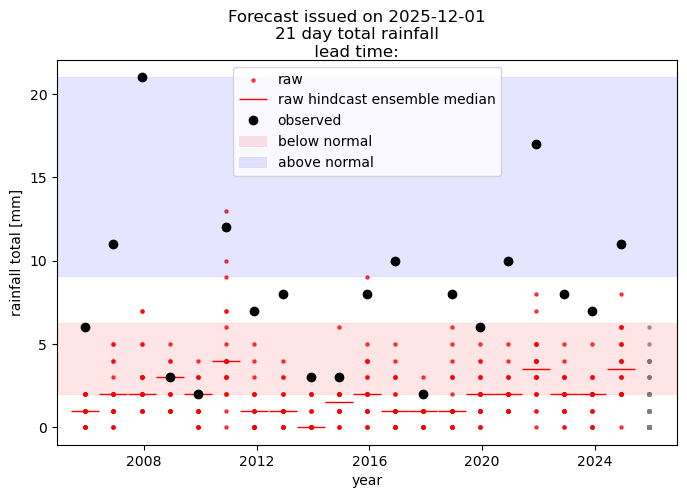

In [10]:
#=============================================================
# Illustrating raw forecast
#=============================================================

lat,lon=-19,48.5

#we will plot it for a selected lead time
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(0, "D")

h_raw=hcst_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")
f_raw=fcst_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

#and observations in the lead-time oriented format
ob=obs_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

#now plotting
fig=plt.figure(figsize=(8,5))

pl=fig.add_subplot(1,1,1)

#plotting hincasts - individual members
for m in h_raw.member:
    pl.scatter(h_raw.valid_time,h_raw.sel(member=m),5, color="red", alpha=0.7)
    
#for labels
pl.scatter(h_raw.valid_time,h_raw.sel(member=m),5, color="red", alpha=0.7, label="raw")

#plotting forecasts - individual members
for m in f_raw.member:
    pl.scatter(f_raw.valid_time,f_raw.sel(member=m),5, color="grey", alpha=0.7)

#and hindcast median
pl.plot(h_raw.valid_time, h_raw.median("member"), "_", ms=20, color="red", label="raw hindcast ensemble median")

#plotting observations
pl.plot(ob.valid_time,ob, "o", color="black", label="observed")

#adding terciles
pl.axhspan(ob.quantile(0.0), ob.quantile(0.33), label="below normal", color="red", alpha=0.1, lw=0.5)
pl.axhspan(ob.quantile(0.66), ob.quantile(1), label="above normal", color="blue", alpha=0.1, lw=0.5)


plt.suptitle("Forecast issued on {}\n{} day total rainfall\n lead time: ".format(nominal_date, window_size, effective_lead_time))

pl.set_xlabel("year")
pl.set_ylabel("rainfall total [mm]")
plt.legend()
plt.show()

In [11]:

# bias correction of aggregated data

#hcst_bc_scaling,fcst_bc_scaling=bias_correct(obs_agg, hcst_agg, fcst_agg, method="scaling", units="mm", pooling="lead", cv=False, kind="*")
#hcst_bc_meanvar,fcst_bc_meanvar=bias_correct(obs_agg, hcst_agg, fcst_agg, method="meanvar", units="mm", pooling="lead", cv=False, kind="*")
hcst_bc_eqm,fcst_bc_eqm=bias_correct(obs_agg, hcst_agg, fcst_agg, method="eqm", units="days", pooling="rolling", window_size=7, cv=False, kind="*")
#hcst_bc_dqm,fcst_bc_eqm=bias_correct(obs_agg, hcst_agg, fcst_agg, method="dqm", units="mm", pooling="lead", cv=False, kind="*")


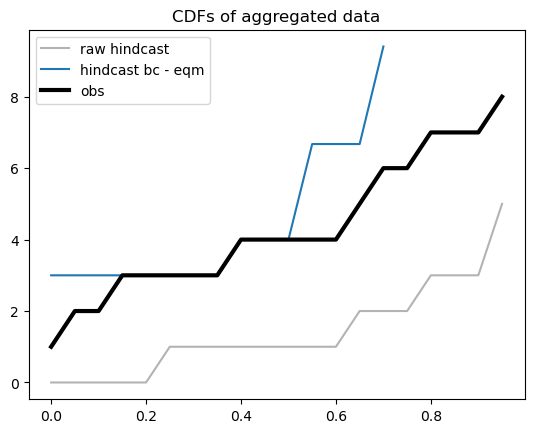

In [12]:
#=============================================================
# Illustrating bias correction
#=============================================================

# here we will use a location
lat,lon=-14,49

#we will plot it for a selected lead time
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(0, "D")

#and ensemble member
member=0

#quick plot of daily data in the first week
y=np.sort(hcst_agg.sel(latitude=lat, longitude=lon, method="nearest", member=member).sel(effective_lead_time=effective_lead_time).data.flatten())
x=np.arange(len(y))/len(y)
plt.plot(x,y, label="raw hindcast", color="0.7")

#y=np.sort(hcst_bc_scaling.sel(latitude=lat, longitude=lon, method="nearest", member=member).sel(effective_lead_time=effective_lead_time).data.flatten())
#x=np.arange(len(y))/len(y)
#plt.plot(x,y, label="hindcast bc - scaling")

#y=np.sort(hcst_bc_meanvar.sel(latitude=lat, longitude=lon, method="nearest", member=member).sel(effective_lead_time=effective_lead_time).data.flatten())
#x=np.arange(len(y))/len(y)
#plt.plot(x,y, label="hindcast bc - meanvar")

y=np.sort(hcst_bc_eqm.sel(latitude=lat, longitude=lon, method="nearest", member=member).sel(effective_lead_time=effective_lead_time).data.flatten())
x=np.arange(len(y))/len(y)
plt.plot(x,y, label="hindcast bc - eqm")

#y=np.sort(hcst_bc_dqm.sel(latitude=lat, longitude=lon, method="nearest", member=member).sel(effective_lead_time=effective_lead_time).data.flatten())
#x=np.arange(len(y))/len(y)
#plt.plot(x,y, label="hindcast bc - dqm")

y=np.sort(obs_agg.sel(latitude=lat, longitude=lon, method="nearest").sel(effective_lead_time=effective_lead_time).data.flatten())
x=np.arange(len(y))/len(y)
plt.plot(x,y, label="obs", color="black", linewidth=3)
plt.legend()

plt.title("CDFs of aggregated data")
plt.show()

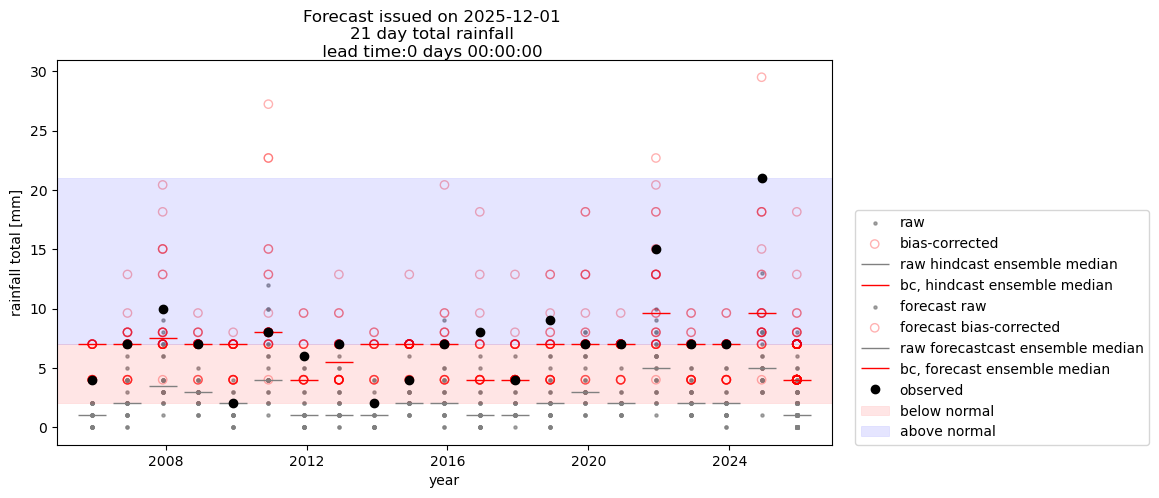

In [13]:
#=============================================================
# Illustrating bias correction
#=============================================================

lat,lon=-19,48
lt=0

#we will plot it for a selected lead time
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(lt, "D")

# we use bias corrected forecast
h_bc=hcst_bc_eqm.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")
f_bc=fcst_bc_eqm.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

h_raw=hcst_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")
f_raw=fcst_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

f_raw=fcst_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

#and observations in the lead-time oriented format
ob=obs_agg.sel(effective_lead_time=effective_lead_time, latitude=lat, longitude=lon, method="nearest")

#now plotting
fig=plt.figure(figsize=(10,5))

pl=fig.add_subplot(1,1,1)

#plotting hincasts - individual members
for m in h_bc.member:
    pl.scatter(h_raw.valid_time,h_raw.sel(member=m),5, color="grey", alpha=0.7)
    pl.scatter(h_bc.valid_time,h_bc.sel(member=m), edgecolors="red", alpha=0.3,facecolors="none")
#for labels
pl.scatter(h_raw.valid_time,h_raw.sel(member=m),5, color="grey", alpha=0.7, label="raw")
pl.scatter(h_bc.valid_time,h_bc.sel(member=m), edgecolors="red", alpha=0.3,facecolors="none", label="bias-corrected")

#and hindcast median
pl.plot(h_raw.valid_time, h_raw.median("member"), "_", ms=20, color="grey", label="raw hindcast ensemble median")
pl.plot(h_bc.valid_time, h_bc.median("member"), "_", ms=20, color="red", label="bc, hindcast ensemble median")


#plotting forecasts - individual members
for m in f_bc.member:
    pl.scatter(f_raw.valid_time,f_raw.sel(member=m),5, color="grey", alpha=0.7)
    pl.scatter(f_bc.valid_time,f_bc.sel(member=m), edgecolors="red", alpha=0.3,facecolors="none")
#for labels
pl.scatter(f_raw.valid_time,f_raw.sel(member=m),5, color="grey", alpha=0.7, label="forecast raw")
pl.scatter(f_bc.valid_time,f_bc.sel(member=m), edgecolors="red", alpha=0.3,facecolors="none", label="forecast bias-corrected")

#and forecast median
pl.plot(f_raw.valid_time, f_raw.median("member"), "_", ms=20, color="grey", label="raw forecastcast ensemble median")
pl.plot(f_bc.valid_time, f_bc.median("member"), "_", ms=20, color="red", label="bc, forecast ensemble median")


#plotting observations
pl.plot(ob.valid_time,ob, "o", color="black", label="observed")

#adding terciles
pl.axhspan(ob.quantile(0.0), ob.quantile(0.33), label="below normal", color="red", alpha=0.1, lw=0.5)
pl.axhspan(ob.quantile(0.66), ob.quantile(1), label="above normal", color="blue", alpha=0.1, lw=0.5)


plt.suptitle("Forecast issued on {}\n{} day total rainfall\n lead time:{} ".format(nominal_date, window_size, effective_lead_time))

pl.set_xlabel("year")
pl.set_ylabel("rainfall total [mm]")
plt.legend(loc=(1.03,0))
plt.show()

In [15]:
#=============================================================
# generating deterministic forecast
#=============================================================

proddet=make_deterministic_product(obs_agg,hcst_bc_eqm,fcst_bc_eqm)

#can save to file
outputfile="{}/{}_{}_{}_{}_detfcst.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)

proddet.to_netcdf(outputfile)
print(f"saved {outputfile}")

#proddet

saved ./data/tp_ECMWF_20251201_madagascar_detfcst.nc


In [16]:
proddet

<xarray.Dataset> Size: 1MB
Dimensions:              (effective_lead_time: 1, valid_time: 1, latitude: 58,
                          longitude: 36, hcst_valid_time: 20)
Coordinates:
  * effective_lead_time  (effective_lead_time) timedelta64[ns] 8B 00:00:00
  * valid_time           (valid_time) datetime64[ns] 8B 2025-12-01
    target_time          (valid_time) datetime64[ns] 8B 2025-12-21
  * latitude             (latitude) float32 232B -25.88 -25.62 ... -11.88 -11.62
  * longitude            (longitude) float32 144B 42.62 42.88 ... 51.12 51.38
  * hcst_valid_time      (hcst_valid_time) datetime64[ns] 160B 2005-12-01 ......
Data variables:
    fcst_mean            (valid_time, effective_lead_time, latitude, longitude) float64 17kB ...
    fcst_anomaly         (valid_time, effective_lead_time, latitude, longitude) float64 17kB ...
    fcst_anomaly_pct     (valid_time, effective_lead_time, latitude, longitude) float64 17kB ...
    hcst_mean            (hcst_valid_time, effective_lead_time, latitude, longitude) float64 334kB ...
    hcst_anomaly         (hcst_valid_time, effective_lead_time, latitude, longitude) float64 334kB ...
    hcst_anomaly_pct     (hcst_valid_time, effective_lead_time, latitude, longitude) float64 334kB ...
    obs                  (hcst_valid_time, effective_lead_time, latitude, longitude) float64 334kB ...
    clim_obs             (effective_lead_time, latitude, longitude) float64 17kB ...
    skill_corr           (effective_lead_time, latitude, longitude) float64 17kB ...
    skill_rmse           (effective_lead_time, latitude, longitude) float64 17kB ...
    skill_bias           (effective_lead_time, latitude, longitude) float64 17kB ...
Attributes: (12/15)
    regrid_direction:         coarse_to_fine
    regrid_method:            bilinear
    regrid_nan_threshold:     0.5
    aggregation_method:       max_dry_spell
    aggregation_window:       21
    bias_correction_method:   eqm
    ...                       ...
    bias_correction_cv:       False
    product:                  deterministic
    units:                    days
    hindcast_period:          2005-2024
    n_hindcast_years:         20
    clim_from:                obs

Text(0.5, 1.0, 'RMSE')

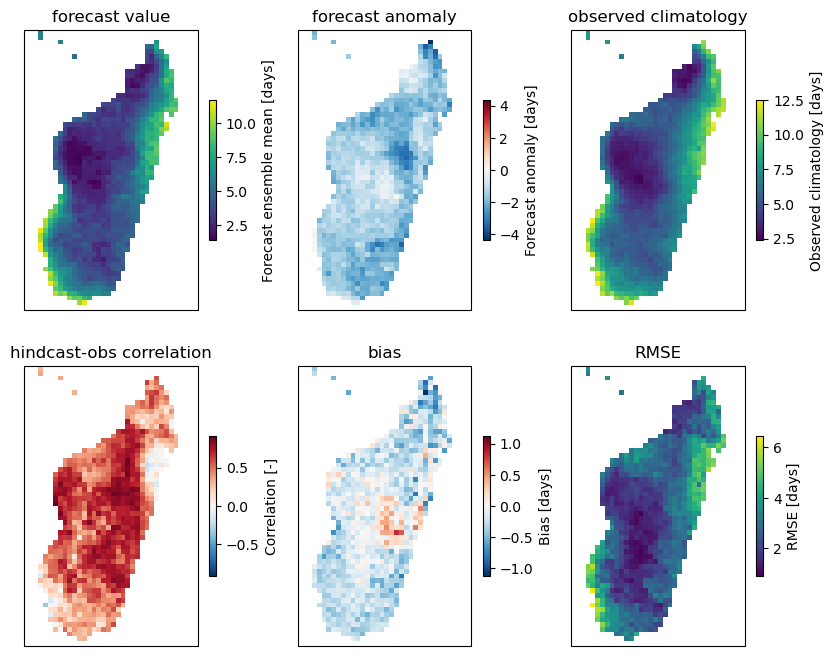

In [17]:
#=============================================================
# plotting deterministic forecast output including skill
#=============================================================

# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(0, "D")

#now plotting
fig=plt.figure(figsize=(10,8))

pl=fig.add_subplot(2,3,1, projection=ccrs.PlateCarree())
proddet["fcst_mean"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("forecast value")

pl=fig.add_subplot(2,3,2, projection=ccrs.PlateCarree())
proddet["fcst_anomaly"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("forecast anomaly")

pl=fig.add_subplot(2,3,3, projection=ccrs.PlateCarree())
proddet["clim_obs"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("observed climatology")

pl=fig.add_subplot(2,3,4, projection=ccrs.PlateCarree())
proddet["skill_corr"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("hindcast-obs correlation")


pl=fig.add_subplot(2,3,5, projection=ccrs.PlateCarree())
proddet["skill_bias"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("bias")

pl=fig.add_subplot(2,3,6, projection=ccrs.PlateCarree())
proddet["skill_rmse"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("RMSE")

In [18]:
#=============================================================
# generating probabilistic forecast
#=============================================================

prodprob=make_probabilistic_product(obs_agg,hcst_bc_eqm,fcst_bc_eqm, quantiles=[0.33,0.66])

#can save to file
outputfile="{}/{}_{}_{}_{}_probfcst.nc".format(data_dir,fcst_var,fcst_model, fcst_date_str, target_domain)

prodprob.to_netcdf(outputfile)
print(f"saved {outputfile}")

prodprob

saved ./data/tp_ECMWF_20251201_madagascar_probfcst.nc


<xarray.Dataset> Size: 3MB
Dimensions:              (longitude: 36, latitude: 58, effective_lead_time: 1,
                          edge: 2, category: 3, valid_time: 1,
                          hcst_valid_time: 20)
Coordinates:
  * longitude            (longitude) float32 144B 42.62 42.88 ... 51.12 51.38
  * latitude             (latitude) float32 232B -25.88 -25.62 ... -11.88 -11.62
  * effective_lead_time  (effective_lead_time) timedelta64[ns] 8B 00:00:00
  * edge                 (edge) float64 16B 0.33 0.66
  * category             (category) int64 24B 0 1 2
    category_label       (category) <U11 132B '<=q0.33' 'q0.33-q0.66' '>q0.66'
  * valid_time           (valid_time) datetime64[ns] 8B 2025-12-01
    target_time          (valid_time) datetime64[ns] 8B 2025-12-21
  * hcst_valid_time      (hcst_valid_time) datetime64[ns] 160B 2005-12-01 ......
Data variables: (12/13)
    threshold_obs        (edge, effective_lead_time, latitude, longitude) float64 33kB ...
    clim_prob            (category) float64 24B 0.33 0.33 0.34
    fcst_prob            (valid_time, effective_lead_time, category, latitude, longitude) float64 50kB ...
    fcst_n_members       (valid_time, effective_lead_time, latitude, longitude) int64 17kB ...
    hcst_prob            (hcst_valid_time, effective_lead_time, category, latitude, longitude) float64 1MB ...
    hcst_n_members       (hcst_valid_time, effective_lead_time, latitude, longitude) int64 334kB ...
    ...                   ...
    obs                  (hcst_valid_time, effective_lead_time, latitude, longitude) float64 334kB ...
    skill_rpss           (effective_lead_time, latitude, longitude) float64 17kB ...
    skill_2afc           (effective_lead_time, latitude, longitude) float64 17kB ...
    skill_roc            (effective_lead_time, category, latitude, longitude) float64 50kB ...
    skill_bss            (effective_lead_time, category, latitude, longitude) float64 50kB ...
    skill_heidke         (effective_lead_time, latitude, longitude) float64 17kB ...
Attributes: (12/17)
    threshold_type:           quantile
    thresholds:               [0.33, 0.66]
    edges_from:               obs
    regrid_direction:         coarse_to_fine
    regrid_method:            bilinear
    regrid_nan_threshold:     0.5
    ...                       ...
    bias_correction_options:  {"kind": "*"}
    bias_correction_cv:       False
    product:                  probabilistic
    units:                    days
    hindcast_period:          2005-2024
    n_hindcast_years:         20

Text(0.5, 1.0, 'Brier skill score above')

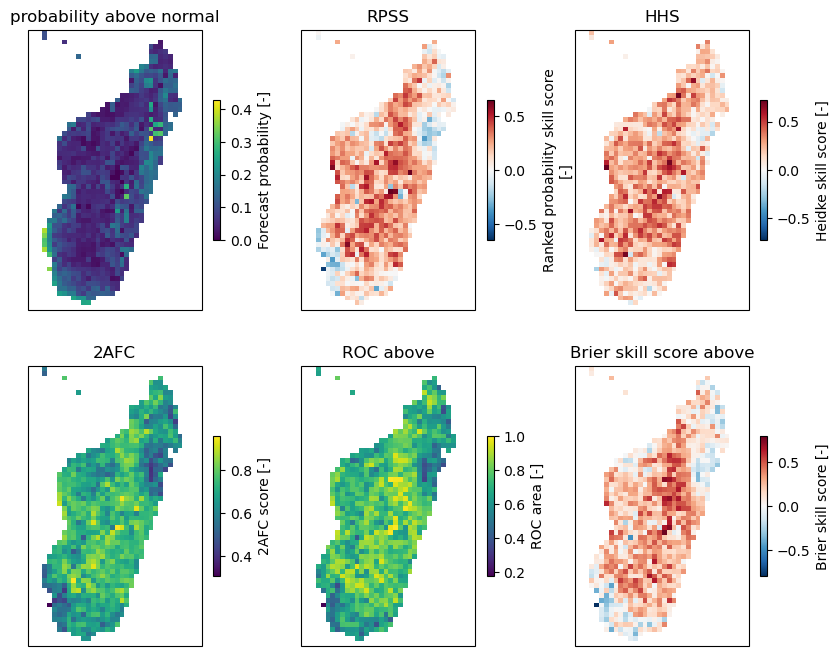

In [19]:
# note that for aggreagated data, lead time is a multiple of aggregation window, so for 7 day it will be 0,7,14
effective_lead_time=pd.to_timedelta(0, "D")

#above normal
category=2

#now plotting
fig=plt.figure(figsize=(10,8))

pl=fig.add_subplot(2,3,1, projection=ccrs.PlateCarree())
prodprob["fcst_prob"].sel(effective_lead_time=effective_lead_time, category=category).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("probability above normal")

pl=fig.add_subplot(2,3,2, projection=ccrs.PlateCarree())
prodprob["skill_rpss"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("RPSS")

pl=fig.add_subplot(2,3,3, projection=ccrs.PlateCarree())
prodprob["skill_heidke"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("HHS")

pl=fig.add_subplot(2,3,4, projection=ccrs.PlateCarree())
prodprob["skill_2afc"].sel(effective_lead_time=effective_lead_time).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("2AFC")

pl=fig.add_subplot(2,3,5, projection=ccrs.PlateCarree())
prodprob["skill_roc"].sel(effective_lead_time=effective_lead_time, category=category).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("ROC above")

pl=fig.add_subplot(2,3,6, projection=ccrs.PlateCarree())
prodprob["skill_bss"].sel(effective_lead_time=effective_lead_time, category=category).plot(cbar_kwargs={"shrink":0.5})
pl.set_title("Brier skill score above")